# 내 보유 종목에 퀀트 전략을 적용했다면?

2024년 9월부터 주식 투자를 하면서 퀀트 트레이딩에 관심이 생겼다. 이론부터 읽기보다, **지금 내가 들고 있는 13개 종목에 퀀트 방식을 적용했다면 어떻게 됐을지** 직접 검증해 보기로 했다.

**질문**
1. 단순한 추세 추종 전략(이동평균 교차)이 그냥 들고 있는 것(Buy & Hold)보다 나았을까?
2. 현대 포트폴리오 이론(MPT)으로 비중을 정했다면 결과가 좋아졌을까?
3. 그 결과는 '미래를 모르는 상태'에서도 재현될까? (워크포워드 검증)

**기간**: 2024-09-01 ~ 2026-10-30 (실제 투자를 시작한 시점부터)

**주의**: 지금 보유 중인 종목은 대부분 이미 많이 오른 종목이고, 이 기간 국내 증시는 강한 상승장이었다. 그래서 결과는 '퀀트가 효과 있다/없다'의 일반적인 증거가 아니라 **이 종목, 이 기간에서의 실험 결과**다. 자세한 한계는 마지막에 정리했다.

## 0. 설정과 데이터

가격 데이터는 `data/fetch_prices.py`로 한 번 받아 `data/prices.csv`에 저장해 두었다. 기간을 고정했기 때문에 언제 실행해도 같은 결과가 나온다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import quant_lib as q
import warnings
warnings.filterwarnings("ignore")

# 한글 폰트 (Colab에서 깨지면: !apt -qq install fonts-nanum 후 런타임 재시작)
for f in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK JP"]:
    if any(f in x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

NAMES = {   # 종목코드: (이름, 구분)
    "360200": ("미국 S&P500 ETF", "ETF"), "458730": ("미국 배당 ETF", "ETF"),
    "323280": ("태성", "코스닥"), "108490": ("로보티즈", "코스닥"),
    "329180": ("HD현대중공업", "코스피"), "012450": ("한화에어로스페이스", "코스피"),
    "261240": ("미국달러선물 ETF", "ETF"), "005930": ("삼성전자", "코스피"),
    "047040": ("대우건설", "코스피"), "064350": ("현대로템", "코스피"),
    "133690": ("미국 나스닥100 ETF", "ETF"), "319640": ("골드선물 ETF", "ETF"),
    "000660": ("SK하이닉스", "코스피"),
}
BENCH = "069500"   # KODEX 200 (KOSPI200)

prices = pd.read_csv("data/prices.csv", index_col="date", parse_dates=True, dtype={})
prices.columns = [c.zfill(6) for c in prices.columns]
TICKERS = list(NAMES)
IS_ETF = {t: NAMES[t][1] == "ETF" for t in TICKERS}
label = lambda t: f"{NAMES[t][0]}"

print(prices.shape, prices.index.min().date(), "~", prices.index.max().date())
print("결측치:", int(prices.isna().sum().sum()))

(523, 14) 2024-09-02 ~ 2026-10-30
결측치: 0


## 1. 이동평균 교차 전략 vs 그냥 보유 (종목별)

**규칙**: 20일 이동평균이 60일 이동평균보다 위에 있으면 보유, 아니면 현금.
- 오늘 종가로 만든 신호는 **다음 날** 포지션에 반영한다. 오늘 종가를 보고 오늘 사는 건 불가능하기 때문이다.
- **거래 비용**: 매수 시 수수료 0.015%, 매도 시 수수료 + 증권거래세 0.20%(주식만, 국내 ETF는 면제).

이 단계는 전체 기간을 한 번에 본 **설명용** 결과다.

In [2]:
hold = prices[TICKERS].pct_change().iloc[1:]
ma = pd.DataFrame({t: q.ma_cross_returns(prices[t], is_etf=IS_ETF[t])[0] for t in TICKERS}).iloc[1:]
trades = {t: int(q.ma_cross_returns(prices[t])[1].diff().abs().sum()) for t in TICKERS}

rows = []
for t in TICKERS:
    mh, mm = q.metrics(hold[t]), q.metrics(ma[t])
    rows.append({"종목": label(t), "보유 CAGR": mh["CAGR"], "전략 CAGR": mm["CAGR"],
                 "보유 샤프": mh["샤프"], "전략 샤프": mm["샤프"],
                 "보유 MDD": mh["MDD"], "전략 MDD": mm["MDD"], "매매 횟수": trades[t]})
single = pd.DataFrame(rows).set_index("종목")
print(f"전략 샤프가 더 높은 종목: {(single['전략 샤프'] > single['보유 샤프']).sum()} / {len(single)}")
print(f"전략 MDD가 더 작은 종목: {(single['전략 MDD'] > single['보유 MDD']).sum()} / {len(single)}")
single.style.format({c: "{:.1%}" for c in single.columns if "CAGR" in c or "MDD" in c} | {"보유 샤프": "{:.2f}", "전략 샤프": "{:.2f}"})

전략 샤프가 더 높은 종목: 4 / 13
전략 MDD가 더 작은 종목: 10 / 13


,보유 CAGR,전략 CAGR,보유 샤프,전략 샤프,보유 MDD,전략 MDD,매매 횟수
종목,,,,,,,
미국 S&P500 ETF,16.7%,12.4%,0.87,0.98,-19.1%,-7.5%,6
미국 배당 ETF,15.8%,8.9%,0.88,0.59,-13.1%,-13.4%,6
태성,61.5%,-24.8%,0.94,-0.19,-73.2%,-65.7%,11
로보티즈,246.2%,173.6%,1.70,1.54,-60.9%,-52.7%,8
HD현대중공업,19.7%,3.5%,0.55,0.24,-63.9%,-51.0%,12
한화에어로스페이스,49.8%,17.8%,0.90,0.52,-55.6%,-39.7%,12
미국달러선물 ETF,3.7%,3.1%,0.17,0.11,-14.1%,-6.5%,12
삼성전자,69.0%,72.2%,1.14,1.31,-42.9%,-48.1%,6
대우건설,59.4%,105.3%,0.94,1.39,-71.4%,-53.7%,8


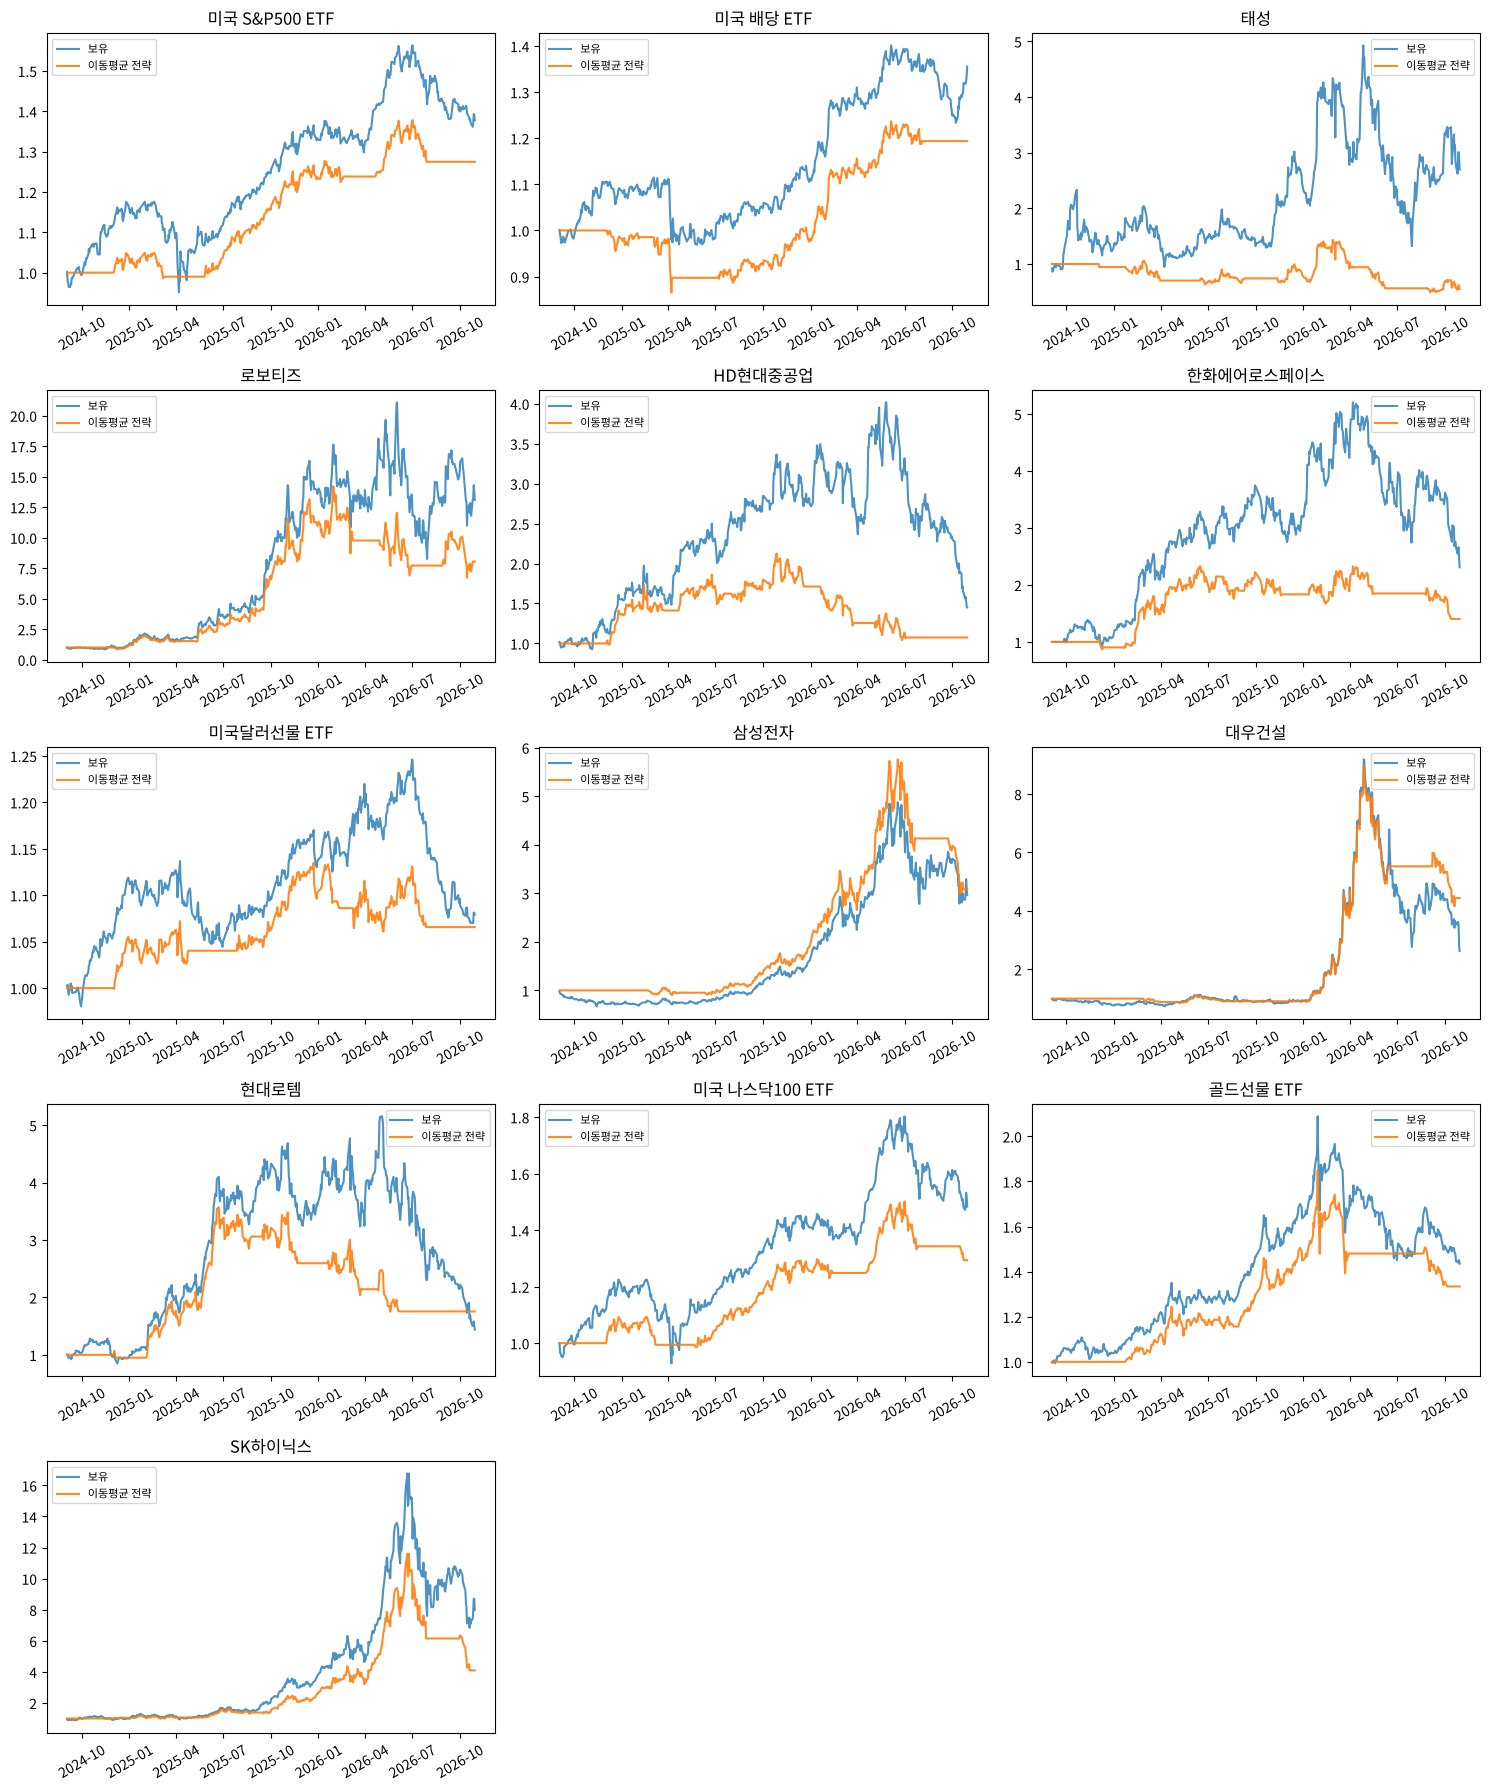

In [3]:
fig, axes = plt.subplots(5, 3, figsize=(15, 18)); axes = axes.flatten()
for ax, t in zip(axes, TICKERS):
    ax.plot((1 + hold[t]).cumprod(), label="보유", alpha=0.8)
    ax.plot((1 + ma[t]).cumprod(), label="이동평균 전략", alpha=0.9)
    ax.set_title(label(t)); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)
for ax in axes[len(TICKERS):]: ax.remove()
plt.tight_layout(); plt.show()

## 2. 전체 기간 최적화와 효율적 프론티어 (참고용)

전체 기간의 평균 수익률과 공분산으로 샤프 지수가 가장 높은 비중을 구한다(종목당 최대 20%).
**전체 기간의 결과를 이미 알고 정한 비중**이라 실제로는 쓸 수 없는 값이다. 비교 기준으로만 본다.

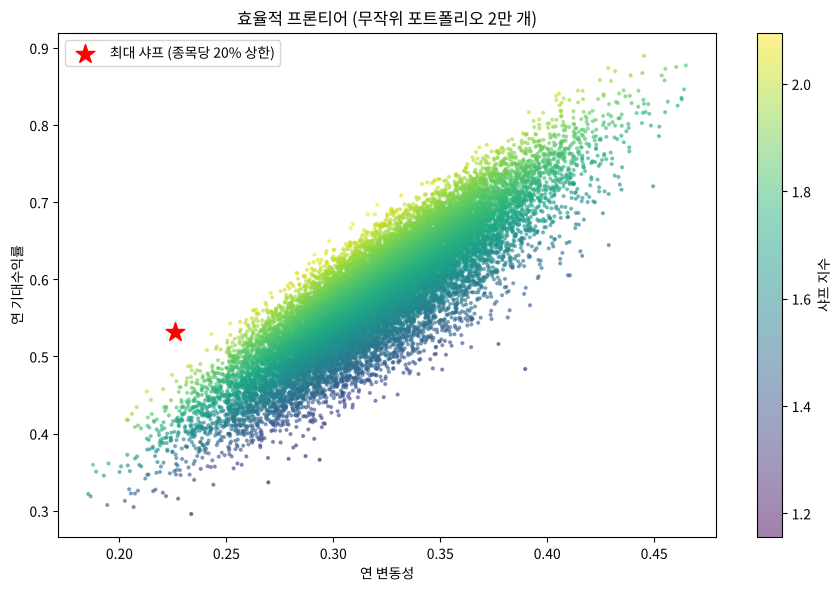

In [4]:
w_full = pd.Series(q.weights_max_sharpe(hold), index=TICKERS)
mu, cov = hold.mean() * 252, hold.cov() * 252

rng = np.random.default_rng(42)
W = rng.random((20000, len(TICKERS))); W /= W.sum(1, keepdims=True)
ret = W @ mu.values; vol = np.sqrt(np.einsum("ij,jk,ik->i", W, cov.values, W))
opt_ret, opt_vol = w_full @ mu, np.sqrt(w_full @ cov @ w_full)

plt.figure(figsize=(9, 6))
sc = plt.scatter(vol, ret, c=(ret - q.RISK_FREE) / vol, s=4, alpha=0.5, cmap="viridis")
plt.colorbar(sc, label="샤프 지수")
plt.scatter(opt_vol, opt_ret, c="red", s=200, marker="*", label="최대 샤프 (종목당 20% 상한)")
plt.xlabel("연 변동성"); plt.ylabel("연 기대수익률"); plt.title("효율적 프론티어 (무작위 포트폴리오 2만 개)")
plt.legend(); plt.tight_layout(); plt.show()

## 3. 지금 비중 vs 최적 비중

실제 보유 비중(2026년 9월 기준, 금액은 공개하지 않고 비중만 기록)과 위의 최적 비중을 비교한다.

In [5]:
current = pd.Series({   # 실제 보유 비중 (%)
    "000660": 28.7, "323280": 10.4, "360200": 9.2, "108490": 8.2, "005930": 7.0,
    "133690": 6.8, "012450": 6.4, "329180": 5.4, "319640": 4.8, "047040": 3.7,
    "261240": 3.4, "458730": 3.2, "064350": 2.8}) / 100
current /= current.sum()
cmp = pd.DataFrame({"현재": current, "최적(전체기간)": w_full})
cmp["차이"] = cmp["최적(전체기간)"] - cmp["현재"]
cmp.index = [label(t) for t in cmp.index]
cmp.sort_values("차이").style.format("{:.1%}")

,현재,최적(전체기간),차이
SK하이닉스,28.7%,14.4%,-14.3%
태성,10.4%,1.0%,-9.4%
삼성전자,7.0%,0.0%,-7.0%
미국 나스닥100 ETF,6.8%,0.0%,-6.8%
HD현대중공업,5.4%,0.0%,-5.4%
현대로템,2.8%,0.0%,-2.8%
대우건설,3.7%,2.1%,-1.6%
한화에어로스페이스,6.4%,7.2%,0.8%
미국 S&P500 ETF,9.2%,10.6%,1.4%
로보티즈,8.2%,11.2%,3.0%


최적 비중은 SK하이닉스처럼 크게 오른 종목을 줄이고, 달러·배당 ETF처럼 다른 종목과 덜 같이 움직이는 자산을 상한(20%)까지 채우는 경향이 있다. 평균 수익률보다 **상관관계가 낮은 자산**을 선호하는 MPT의 구조 때문이다.

이게 실제로 좋은 결정이었는지는 다음 단계에서 미래를 모르는 상태로 검증한다.

## 4. 워크포워드 검증: 미래를 모르는 상태에서 결정했다면

리밸런싱 시점마다 **그 시점까지의 과거 1년(252거래일) 데이터만** 보고 결정하고, 다음 리밸런싱(63거래일, 약 3개월)까지 그대로 운용한다.

각 시점에서 하는 결정
1. 종목별로 이동평균 전략과 보유 중 과거 1년 샤프가 높은 쪽을 고른다 (`전략선택`). 비교를 위해 항상 보유만 하는 경우(`보유만`)도 함께 본다.
2. 아래 네 가지 방법으로 비중을 정한다 (종목당 최대 20%).

| 방법 | 쓰는 정보 | 특징 |
|---|---|---|
| 최대샤프 | 평균 수익률 + 공분산 | 원래 노트북의 방법. 평균 수익률 추정 오차에 민감 |
| 최소분산 | 공분산만 | 변동성이 가장 작은 조합 |
| 리스크패리티 | 공분산만 | 종목마다 위험 기여도를 같게 |
| 동일비중 | 없음 | 비교 기준 |

- 리밸런싱 사이에는 가격 변화에 따라 비중이 자연스럽게 변한다.
- 리밸런싱으로 바뀐 비중만큼 거래 비용을 뺀다.
- 시장 비교: KOSPI200(KODEX 200)을 같은 기간 그냥 보유했을 때.

In [6]:
LOOKBACK, REBAL = 252, 63
results, logs = {}, {}
for sel_name, sel in [("보유만", False), ("전략선택", True)]:
    for m in q.METHODS:
        r, log = q.walk_forward(hold, ma, IS_ETF, method=m, lookback=LOOKBACK, rebalance=REBAL, select_ma=sel)
        results[f"{m} / {sel_name}"] = r; logs[f"{m} / {sel_name}"] = log

period = next(iter(results.values())).index
bench = prices[BENCH].pct_change().loc[period]
results["KOSPI200 보유"] = bench

table = pd.DataFrame({k: q.metrics(v) for k, v in results.items()}).T
table["누적비용"] = [logs[k]["비용"].sum() if k in logs else 0 for k in table.index]
print(f"검증 구간: {period[0].date()} ~ {period[-1].date()} ({len(period)}거래일), 리밸런싱 {len(next(iter(logs.values())))}회")
table.sort_values("샤프", ascending=False).style.format({"CAGR": "{:.1%}", "변동성": "{:.1%}", "샤프": "{:.2f}", "MDD": "{:.1%}", "누적비용": "{:.2%}"})

검증 구간: 2025-09-18 ~ 2026-10-30 (270거래일), 리밸런싱 5회


,CAGR,변동성,샤프,MDD,누적비용
최소분산 / 보유만,45.6%,16.4%,2.23,-12.9%,0.12%
리스크패리티 / 보유만,64.2%,28.6%,1.79,-22.4%,0.14%
리스크패리티 / 전략선택,48.6%,24.3%,1.65,-22.3%,0.13%
동일비중 / 전략선택,67.4%,38.1%,1.48,-30.5%,0.14%
동일비중 / 보유만,69.6%,39.7%,1.47,-31.0%,0.14%
최소분산 / 전략선택,19.2%,11.9%,1.32,-14.4%,0.09%
KOSPI200 보유,87.5%,59.8%,1.31,-41.9%,0.00%
최대샤프 / 보유만,45.5%,35.4%,1.17,-28.4%,0.24%
최대샤프 / 전략선택,26.5%,24.0%,1.00,-23.6%,0.15%


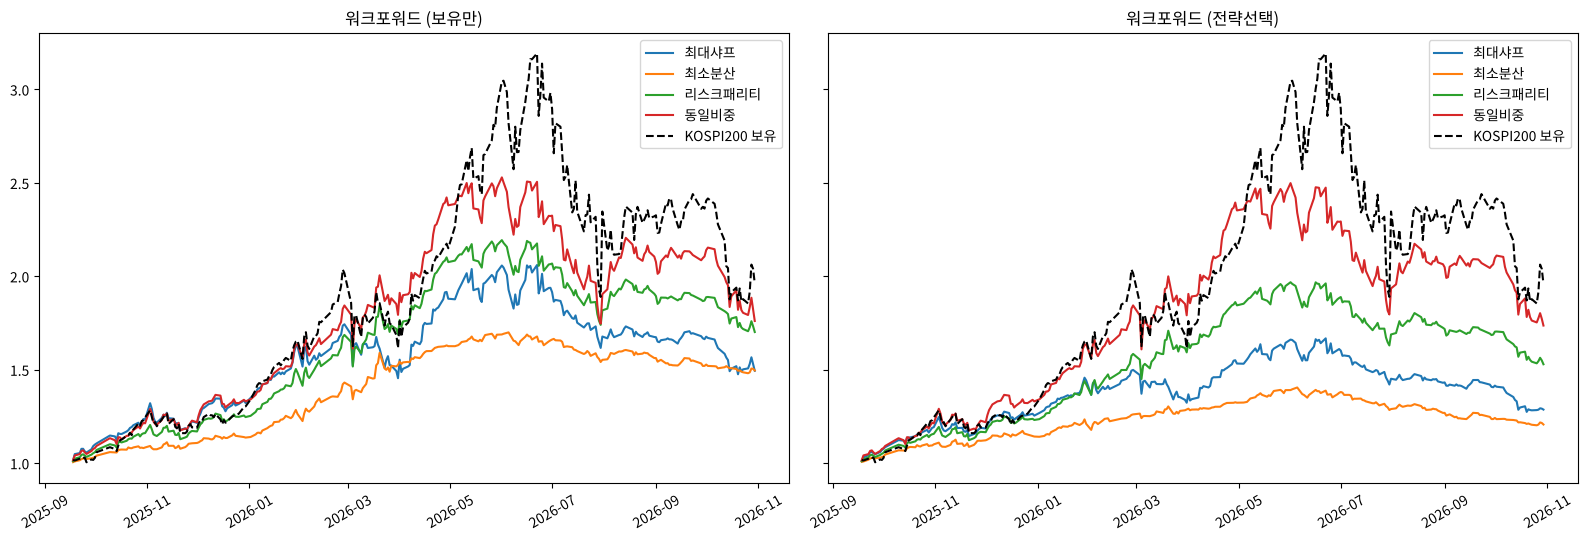

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, sel_name in zip(axes, ["보유만", "전략선택"]):
    for m in q.METHODS:
        ax.plot((1 + results[f"{m} / {sel_name}"]).cumprod(), label=m)
    ax.plot((1 + bench).cumprod(), label="KOSPI200 보유", color="black", linestyle="--")
    ax.set_title(f"워크포워드 ({sel_name})"); ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [8]:
# 최대샤프 방법이 각 시점에 정한 비중
w_hist = logs["최대샤프 / 보유만"][TICKERS]
w_hist.columns = [label(t) for t in TICKERS]
w_hist.style.format("{:.0%}")

,미국 S&P500 ETF,미국 배당 ETF,태성,로보티즈,HD현대중공업,한화에어로스페이스,미국달러선물 ETF,삼성전자,대우건설,현대로템,미국 나스닥100 ETF,골드선물 ETF,SK하이닉스
date,,,,,,,,,,,,,
2025-09-18 00:00:00,8%,0%,4%,10%,12%,6%,20%,0%,0%,13%,0%,20%,8%
2025-12-23 00:00:00,0%,0%,4%,10%,8%,2%,20%,15%,0%,11%,0%,20%,10%
2026-03-31 00:00:00,0%,20%,0%,8%,0%,5%,20%,10%,16%,0%,0%,12%,10%
2026-07-02 00:00:00,20%,20%,0%,1%,0%,0%,20%,4%,3%,0%,20%,0%,12%
2026-10-06 00:00:00,20%,20%,0%,5%,0%,0%,20%,0%,14%,0%,0%,0%,20%


### 4-1. 최근 하락 구간 사례 (2026-06-22 고점 이후)

같은 워크포워드 결과를 KOSPI200 고점(2026-06-22) 이후만 잘라서 본다. 이동평균 전략이 실제로 어떻게 움직였는지 SK하이닉스로 함께 확인한다.

In [9]:
PEAK = "2026-06-22"
case = {m: (1 + results[f"{m} / 보유만"].loc[PEAK:]).prod() - 1 for m in q.METHODS}
case["KOSPI200 보유"] = prices[BENCH].loc[PEAK:].iloc[-1] / prices[BENCH].loc[PEAK:].iloc[0] - 1
case["SK하이닉스 보유"] = prices["000660"].loc[PEAK:].iloc[-1] / prices["000660"].loc[PEAK:].iloc[0] - 1
case["SK하이닉스 이동평균 전략"] = (1 + ma["000660"].loc[PEAK:].iloc[1:]).prod() - 1
print(pd.Series(case).sort_values(ascending=False).map("{:+.1%}".format).to_string())

# SK하이닉스 이동평균 전략의 매매 시점
_, pos = q.ma_cross_returns(prices["000660"])
chg = pos.diff().loc["2026-05-01":]
trades_hx = pd.DataFrame({"행동": chg[chg != 0].map({1.0: "매수", -1.0: "매도"}),
                          "가격": prices["000660"].loc[chg[chg != 0].index]})
print("\nSK하이닉스 고점:", prices["000660"].loc["2026-05-01":].idxmax().date(), f"{prices['000660'].loc['2026-05-01':].max():,.0f}")
trades_hx

최소분산              -10.0%
리스크패리티            -20.6%
최대샤프              -26.0%
동일비중              -28.4%
KOSPI200 보유       -38.6%
SK하이닉스 보유         -52.3%
SK하이닉스 이동평균 전략    -64.7%

SK하이닉스 고점: 2026-06-22 2,919,000


,행동,가격
date,,
2026-07-29,매도,1401000
2026-10-01,매수,1828000
2026-10-21,매도,1288000


이동평균 전략은 고점 대비 이미 절반 가까이 떨어진 뒤에야 매도 신호가 났고, 반등한 뒤 판 가격보다 비싸게 다시 샀다가 또 떨어져 팔았다. 늦게 팔고 늦게 사는 일이 반복되며 손실이 쌓이는 현상(휩쏘)이다.
반면 최소분산은 하락 직전 리밸런싱에서 국내 주식과 덜 같이 움직이는 미국 ETF·달러·금 비중이 높아 손실이 작았다.

## 5. 견고성: 설정을 바꿔도 결론이 유지될까?

리밸런싱 주기(월 21일 / 분기 63일)와 과거 데이터 기간(6개월 126일 / 1년 252일)을 바꿔 같은 비교를 반복한다.
과거 6개월 설정은 검증 구간이 더 길어진다.

In [10]:
rows = []
for lb in [126, 252]:
    for rb in [21, 63]:
        for m in q.METHODS:
            r, log = q.walk_forward(hold, ma, IS_ETF, method=m, lookback=lb, rebalance=rb, select_ma=False)
            b = prices[BENCH].pct_change().loc[r.index]
            mt, mb = q.metrics(r), q.metrics(b)
            rows.append({"과거기간": lb, "리밸런싱": rb, "방법": m, "샤프": mt["샤프"], "MDD": mt["MDD"],
                         "CAGR": mt["CAGR"], "KOSPI200 샤프": mb["샤프"], "KOSPI200 MDD": mb["MDD"]})
robust = pd.DataFrame(rows)
pivot = robust.pivot_table(index=["과거기간", "리밸런싱"], columns="방법", values=["샤프", "MDD"])
pivot.style.format("{:.2f}", subset="샤프").format("{:.1%}", subset="MDD")

In [11]:
# 설정 4가지에서 각 방법이 동일비중보다 나았던 횟수
ew = robust[robust["방법"] == "동일비중"].set_index(["과거기간", "리밸런싱"])
summary = {}
for m in ["최대샤프", "최소분산", "리스크패리티"]:
    d = robust[robust["방법"] == m].set_index(["과거기간", "리밸런싱"])
    summary[m] = {"샤프가 동일비중보다 높음": f"{(d['샤프'] > ew['샤프']).sum()} / 4",
                  "MDD가 동일비중보다 작음": f"{(d['MDD'] > ew['MDD']).sum()} / 4"}
pd.DataFrame(summary).T

,샤프가 동일비중보다 높음,MDD가 동일비중보다 작음
최대샤프,2 / 4,4 / 4
최소분산,2 / 4,4 / 4
리스크패리티,4 / 4,4 / 4


## 6. 추가 실험: 상승장엔 보유, 하락장엔 최소분산으로 갈아탄다면?

"상승장에는 그냥 들고 있고, 하락장에는 최소분산으로 바꾸면 둘의 장점만 얻지 않을까?"를 확인한다.
핵심은 **하락 전환을 얼마나 빨리 알아채느냐**다. 그래서 KOSPI200의 고점·저점(10% 이상 반대로 움직인 지점)을 사후에 정확히 표시해 두고, 그 전환을 0 / 5 / 10 / 20거래일 늦게 알아챘을 때를 비교한다.
0일은 미래를 아는 경우라 실제로는 불가능한 상한선이다. 현실적인 규칙(KOSPI200 이동평균 20일 > 60일이면 상승장)도 함께 본다. 갈아탈 때마다 0.1% 비용을 뺀다.

In [12]:
idx = results["동일비중 / 보유만"].index
ew_r, mv_r = results["동일비중 / 보유만"], results["최소분산 / 보유만"]
bull, pivots = q.zigzag_regime(prices[BENCH].loc[idx[0] - pd.Timedelta(days=7):])
print("전환점:", ", ".join(f"{d.date()} {k}" for d, k in pivots))
print(f"검증 구간 중 하락장 비율: {(~bull.loc[idx]).mean():.0%}\n")

def switch(is_bull, label, cost=0.001):
    b = is_bull.reindex(idx).ffill().fillna(True).astype(bool)
    r = pd.Series(np.where(b, ew_r, mv_r), index=idx) - cost * b.astype(int).diff().abs().fillna(0)
    return q.metrics(r, label)

rows = [q.metrics(ew_r, "동일비중 계속"), q.metrics(mv_r, "최소분산 계속"),
        q.metrics(prices[BENCH].pct_change().loc[idx], "KOSPI200 보유")]
rows += [switch(bull.shift(lag, fill_value=True), f"전환을 {lag}일 늦게 알아챔") for lag in [0, 5, 10, 20]]
trend = (prices[BENCH].rolling(20).mean() > prices[BENCH].rolling(60).mean()).shift(1, fill_value=True)
rows.append(switch(trend, "이동평균으로 판단 (현실적 규칙)"))
pd.DataFrame(rows).style.format({"CAGR": "{:.1%}", "변동성": "{:.1%}", "샤프": "{:.2f}", "MDD": "{:.1%}"})

전환점: 2026-02-26 고점, 2026-03-04 저점, 2026-03-18 고점, 2026-03-31 저점, 2026-06-02 고점, 2026-06-08 저점, 2026-06-22 고점, 2026-07-30 저점, 2026-09-23 고점, 2026-10-26 저점
검증 구간 중 하락장 비율: 23%



,CAGR,변동성,샤프,MDD
동일비중 계속,69.6%,39.7%,1.47,-31.0%
최소분산 계속,45.6%,16.4%,2.23,-12.9%
KOSPI200 보유,87.5%,59.8%,1.31,-41.9%
전환을 0일 늦게 알아챔,204.7%,31.7%,3.60,-10.2%
전환을 5일 늦게 알아챔,108.9%,32.2%,2.38,-19.3%
전환을 10일 늦게 알아챔,77.2%,33.3%,1.81,-23.9%
전환을 20일 늦게 알아챔,49.8%,35.2%,1.25,-33.7%
이동평균으로 판단 (현실적 규칙),66.5%,35.6%,1.54,-34.4%


전환을 정확히 알면 결과가 압도적이지만(샤프 3.60), 5일만 늦어도 수익이 절반으로 줄고(2.38), 10일 늦으면 효과가 대부분 사라지며(1.81, 동일비중 1.47), 20일 늦으면 오히려 동일비중보다 나빠진다(1.25). 하락을 늦게 확인하고 옮기면 이미 많이 떨어진 뒤이고, 곧 이어지는 반등을 피난처에서 놓치기 때문이다. 이 기간에는 10% 넘는 고점·저점이 8개월 동안 10번 나올 만큼 국면이 빨리 바뀌어, 사람이든 규칙이든 제때 따라가기 어려웠다.

## 7. 결론

검증 구간: 2025-09-18 ~ 2026-10-30 (270거래일, 리밸런싱 5회). 이 구간에 KOSPI200은 약 2배(+96%)가 됐지만, 하루에 20% 넘게 오르거나 12% 빠지는 날이 있을 만큼 변동이 컸고 고점 대비 −42%까지 빠지기도 했다.

**1. 이동평균 전략은 수익을 줄이는 대신 낙폭을 줄였다.**
전체 기간 기준으로 13개 중 10개 종목에서 최대 낙폭(MDD)이 작아졌지만, 샤프 지수가 나아진 종목은 4개뿐이었다. 워크포워드에서 과거 1년 성과로 전략/보유를 골랐을 때도 대부분의 방법에서 샤프가 오히려 낮아졌다(예: 최소분산 2.23 → 1.32). 강한 상승장에서 추세 신호가 늦게 들어가고 일찍 빠지면서 상승분을 놓쳤다.

**2. 기대수익률을 쓰는 최대샤프 최적화가 가장 불안정했다.**
원래 노트북의 방법(최대샤프)은 워크포워드 샤프 1.17로 동일비중(1.47)보다 낮았고, 비중이 시점마다 20%와 0% 사이를 크게 오갔다. 과거 1년 평균 수익률은 다음 1년을 잘 예측하지 못하기 때문이다.

**3. 공분산만 쓰는 방법은 낙폭을 꾸준히 줄였다.**
최소분산은 MDD −12.9%(동일비중 −31.0%, KOSPI200 −41.9%)로 가장 안정적이었고 샤프도 가장 높았다(2.23). 리스크패리티는 설정 4가지 모두에서 동일비중보다 샤프가 높고 MDD가 작았다. 설정을 바꿔도 세 최적화 방법 모두 4/4에서 동일비중보다 MDD가 작았다.

**4. 하지만 수익률 자체로는 KOSPI200을 그냥 들고 있는 게 가장 좋았다.**
어떤 방법도 KOSPI200 보유의 CAGR(87.5%)을 넘지 못했다.

**5. 국면에 따라 갈아타는 방법은 전환을 며칠 안에 알아챌 때만 의미가 있었다.**
하락 전환을 5일만 늦게 알아채도 수익이 절반으로 줄었고, 20일 늦으면 그냥 보유보다 나빠졌다. 현실적인 규칙(이동평균)으로 판단하면 그냥 보유와 거의 같았다.

**정리**: 이 종목, 이 기간에서 퀀트 방법은 **수익을 늘리는 도구라기보다 하락 위험을 줄이는 도구**였다. 처음 결론("MPT는 수익보다 하락 위험을 줄인다")은 미래 정보를 제거하고 거래 비용을 넣은 뒤에도 유지됐고, 특히 기대수익률 추정에 의존하지 않는 방법(최소분산, 리스크패리티)에서 더 분명했다. 다만 검증 구간이 1년 남짓이고 상승장이었기 때문에, 이 결론이 다른 시장 상황에서도 맞을지는 더 긴 데이터로 확인해야 한다.

처음 목표는 매일 '사세요/파세요'를 알려주는 도구였다. 이 결과를 보면 매매 신호보다, 목표 비중(예: 최소분산을 일부 섞은 비중)에서 크게 벗어났을 때만 조정을 알려주는 **위험 관리 도구**가 더 근거 있는 방향이다.

## 8. 한계

- **사후 선택 편향**: 지금 보유 중인 종목으로 과거를 테스트했다. 지금 들고 있다는 것 자체가 그동안 성과가 좋았을 가능성이 크다는 뜻이라, 모든 결과가 실제보다 좋게 나올 수 있다.
- **강한 상승장**: 검증 기간 국내 증시는 크게 올랐다. 하락장이나 횡보장에서는 결론이 달라질 수 있다.
- **짧은 기간**: 약 2년 데이터, 워크포워드 리밸런싱은 수 회에 불과하다. 통계적으로 확실한 결론을 내리기엔 표본이 작다.
- **단순화**: 배당, 세금(양도세 등), 체결 가격 차이(슬리피지), 현금 이자는 반영하지 않았다.
- **파라미터**: 이동평균 기간(20/60일)과 비중 상한(20%)은 고정값으로, 최적화하지 않았다.